# 12 final mcap
Builds the final vendor standard mcap file for each episode from the source files on disk.

## Flags
Settings for this run.

In [1]:
FORCE = False
INCLUDE_IMU = True
NUDGE_DUPLICATE_TS = True
NUDGE_NS = 1000
SOURCE_FORMAT_TAG = "source_format:mp4_h264_imu_txt"
ROUND_DECIMALS = 5
COVERAGE_FLOOR_PCT = 30
OUT_DIR = "mcap/final"

## Setup
Imports, paths and small helper functions.

In [2]:
import sys, os, json, csv, hashlib, heapq, random, re, shutil, subprocess, zipfile, time, platform, copy
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version as pkg_version
import numpy as np
import pandas as pd
import yaml
import jsonschema
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import mcap, mcap_protobuf, foxglove_schemas_protobuf, google.protobuf
from mcap.writer import Writer, CompressionType
from mcap.reader import make_reader
from foxglove_schemas_protobuf.CompressedVideo_pb2 import CompressedVideo
try:
    from mcap_protobuf.schema import build_file_descriptor_set
except Exception:
    build_file_descriptor_set = None

NB_NAME = "12_final_mcap.ipynb"
run_start = datetime.now(timezone.utc)
t_run = time.time()

class Stop(RuntimeError):
    pass

ROOT = Path.cwd().parent
if not (ROOT / "configs" / "config.yaml").exists():
    raise Stop(f"configs/config.yaml not found in {ROOT}; run the notebook from the notebooks folder")

REP = ROOT / "reports"
EPI = ROOT / "episodes"
CAL = ROOT / "calib"
V13 = ROOT / "mcap" / "v1_3"
OUT = ROOT / OUT_DIR
if OUT.resolve() == V13.resolve():
    raise Stop("OUT_DIR must not be the v1_3 folder")
OUT.mkdir(parents=True, exist_ok=True)
(REP / "12_metadata_final").mkdir(parents=True, exist_ok=True)

CAMS = ["cam_high", "cam_left_wrist", "cam_right_wrist", "cam_ext"]
BODY = {"cam_high": "head", "cam_left_wrist": "left", "cam_right_wrist": "right"}
HANDS = ["left", "right"]
T_VID = {c: f"/cameras/{c}" for c in CAMS}
T_IMU = {c: f"/ego/imu/{c}" for c in BODY}
T_HAND = {h: f"/ego/hand/joints/{h}/position" for h in HANDS}
T_INT = "/ego/calibration/intrinsics"
T_EXT = "/ego/calibration/extrinsics"
RANK = {T_INT: 0, T_EXT: 1}
for i, c in enumerate(CAMS):
    RANK[T_VID[c]] = 2 + i
for i, c in enumerate(BODY):
    RANK[T_IMU[c]] = 6 + i
RANK[T_HAND["left"]] = 9
RANK[T_HAND["right"]] = 10
TOPIC_CAM = {T_VID[c]: c for c in CAMS}
TOPIC_IMU = {T_IMU[c]: c for c in BODY}
TOPIC_HAND = {T_HAND[h]: h for h in HANDS}
SCHEMA_NAME = {T_INT: "ego.Intrinsics", T_EXT: "ego.Extrinsics"}
SCHEMA_NAME.update({t: "foxglove.CompressedVideo" for t in TOPIC_CAM})
SCHEMA_NAME.update({t: "ego.ImuSample" for t in TOPIC_IMU})
SCHEMA_NAME.update({t: "ego.HandJoints" for t in TOPIC_HAND})
CHUNK = 4 * 1024 * 1024

def expected_topics():
    t = [T_INT, T_EXT] + [T_VID[c] for c in CAMS]
    if INCLUDE_IMU:
        t += [T_IMU[c] for c in BODY]
    return t + [T_HAND[h] for h in HANDS]

def group_of(topic):
    if topic in TOPIC_CAM: return "video"
    if topic in TOPIC_IMU: return "imu"
    if topic in TOPIC_HAND: return "hand"
    return "calibration"

def ver(name):
    try:
        return pkg_version(name)
    except Exception:
        return "unknown"

VERSIONS = {"python": platform.python_version(), "mcap": ver("mcap"), "mcap_protobuf": ver("mcap-protobuf-support"),
            "foxglove_schemas_protobuf": ver("foxglove-schemas-protobuf"), "protobuf": ver("protobuf"), "numpy": ver("numpy")}

def sha256_file(p, block=1 << 22):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        while True:
            b = f.read(block)
            if not b: break
            h.update(b)
    return h.hexdigest()

def jdump(x):
    return json.dumps(x, separators=(",", ":"), ensure_ascii=False, allow_nan=False)

def as_str(x):
    return x if isinstance(x, str) else jdump(x)

def short(x, n=200):
    x = str(x)
    return x if len(x) <= n else x[:n - 3] + "..."

def tobool(x):
    return str(x).strip().lower() in ("true", "1", "yes", "y")

def ts_obj(t):
    t = int(t)
    return {"sec": t // 10**9, "nsec": t % 10**9}

def iso_to_ns(s):
    d = datetime.fromisoformat(str(s).replace("Z", "+00:00"))
    if d.tzinfo is None:
        d = d.replace(tzinfo=timezone.utc)
    delta = d - datetime(1970, 1, 1, tzinfo=timezone.utc)
    return (delta.days * 86400 + delta.seconds) * 10**9 + delta.microseconds * 1000

def bad_const(x):
    raise ValueError("bad json constant " + x)

print("root:", ROOT)
print("out:", OUT)
print(VERSIONS)

c:\workstation\3RD YEAR\ego_pipeline\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


root: c:\workstation\3RD YEAR\ego_pipeline
out: c:\workstation\3RD YEAR\ego_pipeline\mcap\final
{'python': '3.13.13', 'mcap': '1.5.0', 'mcap_protobuf': '0.5.4', 'foxglove_schemas_protobuf': '0.4.0', 'protobuf': '7.36.2', 'numpy': '2.5.4'}


## Check files
Checks that every file named in the task exists before anything is read.

In [3]:
problems = []
def need(p):
    if not Path(p).exists():
        problems.append("missing " + str(Path(p).relative_to(ROOT)))

def report_problems(items):
    print(f"{len(items)} problem(s):")
    for x in items[:50]:
        print(" -", x)
    raise Stop("hard gate failed, see the list above")

for g in ["reports/06_summary.json", "reports/06_anchor_estimate.json", "reports/08b_exo_sync.json", "reports/09c_coverage.csv",
          "reports/09c_summary.json", "reports/09b_hand_schema.json", "reports/08e_imu_schema.json",
          "reports/11_calibration_schema.json", "reports/09b_mcap_manifest.csv", "reports/10_hypothesis_check.csv",
          "configs/hand_layout.yaml", "configs/config.yaml"]:
    need(ROOT / g)
if problems:
    report_problems(problems)

ids = json.load(open(REP / "06_summary.json", encoding="utf-8"))["episode_ids"]
if len(ids) != 4:
    raise Stop(f"expected 4 episode ids, found {len(ids)}")

for eid in ids:
    ed = EPI / eid
    for f in ["frames_head.npz", "frames_left.npz", "frames_right.npz", "episode_metadata_draft.json", "hand_left.npz",
              "hand_right.npz", "language.json", "video/cam_ext_timestamps.npz"]:
        need(ed / f)
    for c in CAMS:
        need(ed / "video" / f"{c}.h264")
        need(ed / "video" / f"{c}_au.npz")
    need(CAL / f"{eid}_calibration.json")
    need(V13 / f"{eid}.mcap")
if problems:
    report_problems(problems)
print("episodes:", ids)
print("all files found")

episodes: ['vendorX_2026-10-11_op01_000001', 'vendorX_2026-10-11_op01_000002', 'vendorX_2026-10-11_op01_000003', 'vendorX_2026-10-11_op01_000004']
all files found


## Load sources
Reads the small source files into memory. Video streams are only read later in pieces.

In [4]:
cfg = yaml.safe_load(open(ROOT / "configs" / "config.yaml", encoding="utf-8"))
print("config keys:", list(cfg.keys()) if isinstance(cfg, dict) else type(cfg))
layout = yaml.safe_load(open(ROOT / "configs" / "hand_layout.yaml", encoding="utf-8"))
print("layout keys:", list(layout.keys()))
jj = layout["joints"]
if isinstance(jj, dict):
    JOINTS = [str(k) for k in jj.keys()]
else:
    JOINTS = [str(j["name"]) if isinstance(j, dict) else str(j) for j in jj]
if len(JOINTS) != 25:
    raise Stop(f"layout has {len(JOINTS)} joints, expected 25")

anchor = json.load(open(REP / "06_anchor_estimate.json", encoding="utf-8"))
sync = json.load(open(REP / "08b_exo_sync.json", encoding="utf-8"))
zero_us = int(anchor["session_zero_utc_us"])
s09 = json.load(open(REP / "09c_summary.json", encoding="utf-8"))
print("09c_summary keys:", list(s09.keys()))
COV = pd.read_csv(REP / "09c_coverage.csv")

def find_schema(obj, name):
    short_name = name.split(".")[-1].lower()
    if isinstance(obj, dict):
        for k, v in obj.items():
            if isinstance(v, dict) and (k == name or str(k).lower().endswith(short_name)):
                r = find_schema(v, name)
                if r is not None: return r
        if "properties" in obj and ("type" in obj or "$schema" in obj):
            return obj
        for v in obj.values():
            r = find_schema(v, name)
            if r is not None: return r
    return None

SCHEMAS = {}
for topic, fname, nm in [("imu", "08e_imu_schema.json", "ego.ImuSample"), ("hand", "09b_hand_schema.json", "ego.HandJoints"),
                         ("ext", "11_calibration_schema.json", "ego.Extrinsics")]:
    raw_obj = json.load(open(REP / fname, encoding="utf-8"))
    print(fname, "keys:", list(raw_obj.keys())[:8] if isinstance(raw_obj, dict) else type(raw_obj))
    sch = find_schema(raw_obj, nm)
    if sch is None:
        raise Stop(f"no json schema found inside {fname}")
    SCHEMAS[topic] = sch

num_or_null = lambda n=None: ({"type": ["array", "null"], "items": {"type": "number"}} if n is None else
                              {"type": ["array", "null"], "items": {"type": "number"}, "minItems": n, "maxItems": n})
fov_item = {"type": "object", "properties": {k: {"type": ["number", "null"]} for k in ("horizontal", "vertical", "diagonal")},
            "required": ["horizontal", "vertical", "diagonal"], "additionalProperties": False}
cam_props = {"camera_name": {"type": "string"}, "frame_id": {"type": "string"}, "image_frame_id": {"type": "string"},
             "width": {"type": ["integer", "null"]}, "height": {"type": ["integer", "null"]},
             "distortion_model": {"type": ["string", "null"]}, "D": num_or_null(), "K": num_or_null(9),
             "R": num_or_null(9), "P": num_or_null(12), "fov_rad": fov_item,
             "status": {"type": "object", "additionalProperties": {"type": "string"}}, "source": {"type": "string"}}
INTRINSICS_SCHEMA = {
    "$schema": "http://json-schema.org/draft-07/schema#", "title": "ego.Intrinsics", "type": "object",
    "properties": {"timestamp": {"type": "object", "properties": {"sec": {"type": "integer"}, "nsec": {"type": "integer"}},
                                 "required": ["sec", "nsec"], "additionalProperties": False},
                   "calibration_id": {"type": "string"},
                   "cameras": {"type": "array", "items": {"type": "object", "properties": cam_props,
                                                           "required": list(cam_props.keys()), "additionalProperties": False}}},
    "required": ["timestamp", "calibration_id", "cameras"], "additionalProperties": False}
SCHEMAS["int"] = INTRINSICS_SCHEMA
with open(REP / "12_intrinsics_schema.json", "w", encoding="utf-8") as f:
    json.dump(INTRINSICS_SCHEMA, f, indent=2)

def make_validator(schema):
    cls = jsonschema.validators.validator_for(schema, default=jsonschema.Draft7Validator)
    cls.check_schema(schema)
    return cls(schema)
VALIDATORS = {T_INT: make_validator(SCHEMAS["int"]), T_EXT: make_validator(SCHEMAS["ext"])}
VALIDATORS.update({T_IMU[c]: make_validator(SCHEMAS["imu"]) for c in BODY})
VALIDATORS.update({T_HAND[h]: make_validator(SCHEMAS["hand"]) for h in HANDS})
print("schemas ready")

config keys: ['source_root', 'directories', 'devices', 'nominal_fps', 'chunk_seconds_hypothesis', 'thresholds', 'time', 'identity']
layout keys: ['provisional', 'note', 'joints', 'mediapipe_mapping']
09c_summary keys: ['camera', 'assignment', 'label_mapping_before', 'created_utc', 'settings', 'episodes_total', 'episodes_done', 'episodes_failed', 'episodes', 'tests', 'low_coverage_episodes']
08e_imu_schema.json keys: ['$schema', 'title', 'description', 'type', 'properties', 'required', 'additionalProperties']
09b_hand_schema.json keys: ['$schema', 'title', 'type', 'properties', 'required', 'additionalProperties']
11_calibration_schema.json keys: ['$schema', 'title', 'type', 'additionalProperties', 'required', 'properties']
schemas ready


## Source helpers
Functions to read the npz files, count access units and build timestamps.

In [5]:
def pick(z, *parts):
    keys = list(z.keys())
    for p in parts:
        for k in keys:
            if p in k.lower():
                return k
    return None

def scalar_str(x):
    if x is None: return ""
    a = np.asarray(x)
    return str(a.reshape(-1)[0]) if a.size else ""

def load_npz(p):
    z = np.load(p, allow_pickle=True)
    return {k: z[k] for k in z.files}

def load_src(eid):
    ed = EPI / eid
    s = {"eid": eid}
    s["draft"] = json.load(open(ed / "episode_metadata_draft.json", encoding="utf-8"))
    s["lang"] = json.load(open(ed / "language.json", encoding="utf-8"))
    s["frames"] = {c: load_npz(ed / f"frames_{d}.npz") for c, d in BODY.items()}
    s["hand"] = {h: load_npz(ed / f"hand_{h}.npz") for h in HANDS}
    s["ext"] = load_npz(ed / "video" / "cam_ext_timestamps.npz")
    s["au"] = {c: load_npz(ed / "video" / f"{c}_au.npz") for c in CAMS}
    s["h264"] = {c: ed / "video" / f"{c}.h264" for c in CAMS}
    return s

def to_i64(a):
    a = np.asarray(a)
    return a.astype(np.int64) if a.dtype.kind in "iu" else np.rint(a).astype(np.int64)

def raw_times(s):
    t = {}
    for c in BODY:
        t[c] = (zero_us + to_i64(s["frames"][c]["ts_session_us"])) * 1000
    t["cam_ext"] = to_i64(s["ext"]["ts_utc_ns"])
    return t

def nudge_times(t):
    t = t.copy()
    rec = []
    if not NUDGE_DUPLICATE_TS:
        return t, rec
    bad = np.nonzero(np.diff(t) <= 0)[0]
    if len(bad) == 0:
        return t, rec
    for i in range(int(bad[0]) + 1, len(t)):
        if t[i] <= t[i - 1]:
            new = t[i - 1] + NUDGE_NS
            rec.append((i, int(t[i]), int(new)))
            t[i] = new
    return t, rec

def count_aud(p, block=1 << 24):
    n = 0
    carry = np.zeros(0, dtype=np.uint8)
    with open(p, "rb") as f:
        while True:
            b = f.read(block)
            if not b: break
            a = np.concatenate([carry, np.frombuffer(b, dtype=np.uint8)])
            if len(a) >= 4:
                m = (a[:-3] == 0) & (a[1:-2] == 0) & (a[2:-1] == 1) & ((a[3:] & 0x1F) == 9)
                n += int(m.sum())
            carry = a[-3:]
    return n

def au_table(z, fsize):
    ko = pick(z, "offset", "start", "pos")
    ks = pick(z, "size", "length", "len")
    if ko is None:
        raise ValueError("no offset array in au table, keys: " + str(list(z.keys())))
    offs = np.asarray(z[ko]).astype(np.int64).reshape(-1)
    if ks is not None:
        sizes = np.asarray(z[ks]).astype(np.int64).reshape(-1)
    else:
        sizes = np.diff(np.append(offs, fsize))
    return offs, sizes

def hand_arrays(h):
    P = np.asarray(h["position"], dtype=np.float32)
    C = np.asarray(h["confidence"], dtype=np.float32)
    if "joints" in h:
        names = [str(x) for x in np.asarray(h["joints"]).reshape(-1)]
        if names != JOINTS:
            if sorted(names) != sorted(JOINTS):
                raise ValueError("joint names in hand npz differ from layout")
            idx = [names.index(j) for j in JOINTS]
            P, C = P[:, idx], C[:, idx]
    det = np.asarray(h["detected"]).astype(bool).reshape(-1)
    oof = np.asarray(h["out_of_frame"]).astype(bool).reshape(-1)
    if "tracked" in h:
        trk = np.asarray(h["tracked"]).astype(bool).reshape(-1)
    else:
        Cn = np.nan_to_num(C)
        cnt = (Cn > 0).sum(axis=1)
        mean = Cn.sum(axis=1) / np.maximum(cnt, 1)
        trk = (cnt >= 15) & (mean >= 0.5)
    return {"P": P, "C": C, "det": det, "trk": trk, "oof": oof}
print("helpers ready")

helpers ready


## Hard gates
Stops the notebook if any of the input checks fail.

In [6]:
gp = []
hyp10 = pd.read_csv(REP / "10_hypothesis_check.csv")
print("10_hypothesis_check columns:", list(hyp10.columns))
idc = "id" if "id" in hyp10.columns else hyp10.columns[0]
resc = "result" if "result" in hyp10.columns else hyp10.columns[-1]
mask = hyp10[idc].astype(str).str.match(r"^L[1-5](?!\d)")
if int(mask.sum()) == 0:
    gp.append("no L1 to L5 rows in 10_hypothesis_check.csv")
badrows = hyp10[mask & hyp10[resc].astype(str).str.upper().isin(["FAIL", "FLAG"])]
for _, r in badrows.iterrows():
    gp.append(f"10_hypothesis_check {r[idc]} is {r[resc]}")

man09 = pd.read_csv(REP / "09b_mcap_manifest.csv")
if abs(float(anchor["lag_s"]) - float(sync["lag_s"])) > 0.05:
    gp.append(f"lag_s differs: {anchor['lag_s']} vs {sync['lag_s']}")

SRC, CALS = {}, {}
first_keys_done = False
for eid in ids:
    try:
        rows = man09[man09["episode_id"].astype(str) == eid]
        if len(rows) > 1:
            sub = rows[rows["path"].astype(str).str.contains("v1_3")]
            rows = sub if len(sub) else rows
        got = sha256_file(V13 / f"{eid}.mcap")
        if got not in set(rows["sha256"].astype(str).str.lower()):
            gp.append(f"{eid}: v1_3 sha256 does not match 09b manifest")
        s = load_src(eid)
        SRC[eid] = s
        CALS[eid] = json.load(open(CAL / f"{eid}_calibration.json", encoding="utf-8"))
        if not first_keys_done:
            first_keys_done = True
            print("keys, episode", eid)
            print(" frames_head:", sorted(s["frames"]["cam_high"].keys()))
            print(" hand_left:", sorted(s["hand"]["left"].keys()))
            print(" cam_au:", sorted(s["au"]["cam_high"].keys()))
            print(" cam_ext_timestamps:", sorted(s["ext"].keys()))
            print(" calibration:", sorted(CALS[eid].keys()))
        raw = raw_times(s)
        s["raw"] = raw
        n_head = len(raw["cam_high"])
        for h in HANDS:
            hz = s["hand"][h]
            if scalar_str(hz.get("assignment")) != "position_continuity_v1":
                gp.append(f"{eid} hand {h}: assignment is '{scalar_str(hz.get('assignment'))}'")
            if np.asarray(hz["position"]).shape[0] != n_head:
                gp.append(f"{eid} hand {h}: n {np.asarray(hz['position']).shape[0]} != cam_high {n_head}")
            tag = scalar_str(hz.get("position_tag"))
            if tag and tag != "hand_2d_normalized":
                gp.append(f"{eid} hand {h}: position_tag '{tag}'")
        d0 = abs(int(raw["cam_high"][0]) - iso_to_ns(s["draft"]["capture_start_iso"]))
        if d0 > 1_000_000:
            gp.append(f"{eid}: first cam_high frame is {d0 / 1e6:.2f} ms from capture_start_iso")
        s["aud"] = {}
        for c in CAMS:
            fsize = s["h264"][c].stat().st_size
            offs, sizes = au_table(s["au"][c], fsize)
            n_aud = count_aud(s["h264"][c])
            s["aud"][c] = n_aud
            if not (n_aud == len(offs) == len(raw[c])):
                gp.append(f"{eid} {c}: aud {n_aud}, au table {len(offs)}, timestamps {len(raw[c])}")
            if len(offs) and (offs[0] != 0 or np.any(offs[:-1] + sizes[:-1] != offs[1:]) or offs[-1] + sizes[-1] != fsize):
                gp.append(f"{eid} {c}: au table does not cover the h264 file")
    except Exception as e:
        gp.append(f"{eid}: {type(e).__name__}: {e}")
if gp:
    report_problems(gp)

RIG_FIXED = len({jdump(CALS[e].get("extrinsics")) for e in ids}) == 1
print("gates passed for", len(ids), "episodes")
print(pd.DataFrame({e: {c: len(SRC[e]["raw"][c]) for c in CAMS} for e in ids}).T.to_string())

10_hypothesis_check columns: ['id', 'hypothesis', 'measured', 'result']
keys, episode vendorX_2026-10-11_op01_000001
 frames_head: ['acc', 'flags', 'global_n', 'gyro', 'local_i', 'source_clip', 'source_clips', 'ts_session_us']
 hand_left: ['assignment', 'confidence', 'detected', 'frame_index', 'joints', 'out_of_frame', 'position', 'position_tag', 'timestamp', 'tracked']
 cam_au: ['first_is_aud', 'frame_index', 'is_key', 'n_pps', 'n_sps', 'n_vcl', 'offsets', 'sizes']
 cam_ext_timestamps: ['flag', 'pts_s', 'root_frame_idx', 'ts_utc_ns']
 calibration: ['calibration_id', 'cameras', 'conventions', 'created_utc', 'deviations', 'episode_id', 'extrinsics', 'image_orientation_note', 'rig_fixed_across_batch', 'rig_fixed_note', 'schema_version']
gates passed for 4 episodes
                                cam_high  cam_left_wrist  cam_right_wrist  cam_ext
vendorX_2026-10-11_op01_000001     21240           21239            21239    21269
vendorX_2026-10-11_op01_000002      9390            9390     

## Templates
Reads the v1_3 files only to copy the metadata record and the channel records.

In [7]:
IMU_KEYS = ["timestamp", "frame_id", "sample_index", "linear_acceleration", "angular_velocity", "quality_flags", "valid"]

def read_v13(eid):
    out = {"channels": {}, "first": {}, "meta": None}
    with open(V13 / f"{eid}.mcap", "rb") as f:
        r = make_reader(f)
        sm = r.get_summary()
        for ch in sm.channels.values():
            out["channels"][ch.topic] = {"enc": ch.message_encoding, "meta": dict(ch.metadata), "schema": sm.schemas.get(ch.schema_id)}
        for md_ in r.iter_metadata():
            if md_.name == "episode_metadata":
                out["meta"] = dict(md_.metadata)
        tops = [T_HAND[h] for h in HANDS] + ([T_IMU[c] for c in BODY] if INCLUDE_IMU else [])
        for tp in tops:
            msgs = []
            for _, _, m in r.iter_messages(topics=[tp]):
                msgs.append(json.loads(m.data))
                if len(msgs) >= 200: break
            out["first"][tp] = msgs
    return out

def vec_keys(msgs):
    for m in msgs:
        v = m.get("linear_acceleration")
        if isinstance(v, dict): return list(v.keys())
        if isinstance(v, list): return None
    return ["x", "y", "z"]

class HandBuilder:
    def __init__(self, msgs, side):
        self.side = side
        self.tpl = msgs[0]
        self.jkey = None
        for k, v in self.tpl.items():
            if isinstance(v, list) and len(v) == len(JOINTS) and isinstance(v[0], dict):
                self.jkey = k
        if self.jkey is None:
            raise ValueError("no joint list found in the v1_3 hand message")
        self.jtpl = self.tpl[self.jkey][0]
        self.name_key = next((k for k, v in self.jtpl.items() if isinstance(v, str)), None)
        if self.name_key:
            names = [j.get(self.name_key) for j in self.tpl[self.jkey]]
            if names != JOINTS:
                print("note: v1_3 joint names differ from layout, layout order is used")

    def joints(self, pos, conf):
        out = []
        for j in range(len(JOINTS)):
            x, y, z = pos[j]
            if np.isfinite(x) and np.isfinite(y):
                p = {"x": round(float(x), ROUND_DECIMALS), "y": round(float(y), ROUND_DECIMALS),
                     "z": round(float(z), ROUND_DECIMALS) if np.isfinite(z) else None}
                c = round(float(conf[j]), ROUND_DECIMALS) if np.isfinite(conf[j]) else 0.0
            else:
                p, c = None, 0.0
            d = {}
            for k, v in self.jtpl.items():
                if k == self.name_key: d[k] = JOINTS[j]
                elif k == "position": d[k] = p
                elif k == "orientation": d[k] = None
                elif k == "confidence": d[k] = c
                else: d[k] = copy.deepcopy(v)
            out.append(d)
        return out

    def msg(self, k, t, pos, conf, det, trk, oof):
        m = {}
        for key, v in self.tpl.items():
            if key == "timestamp": m[key] = ts_obj(t)
            elif key == "frame_id": m[key] = "CamHighImage"
            elif key == "position_tag": m[key] = "hand_2d_normalized"
            elif key == "detected": m[key] = bool(det)
            elif key == "tracked": m[key] = bool(trk)
            elif key == "out_of_frame": m[key] = bool(oof)
            elif key == self.jkey: m[key] = self.joints(pos, conf)
            elif key in ("sample_index", "frame_index", "sequence"): m[key] = int(k)
            elif isinstance(v, str) and v in ("left", "right"): m[key] = self.side
            else: m[key] = copy.deepcopy(v)
        return m

def imu_msg(cam, i, t, acc, gyro, ts_src, keys):
    flags = 0
    if i > 0 and ts_src[i] == ts_src[i - 1]: flags |= 1
    if i > 0 and np.array_equal(acc[i], acc[i - 1]): flags |= 2
    zero = (not np.any(acc[i])) and (not np.any(gyro[i]))
    if zero:
        flags |= 4
        kk = keys or ["x", "y", "z"]
        la, av, valid = {k: None for k in kk}, {k: None for k in kk}, False
    else:
        la, av, valid = acc[i].tolist(), gyro[i].tolist(), True
        if keys:
            la, av = dict(zip(keys, la)), dict(zip(keys, av))
    return {"timestamp": ts_obj(t), "frame_id": cam, "sample_index": int(i), "linear_acceleration": la,
            "angular_velocity": av, "quality_flags": flags, "valid": valid}
print("templates ready")

templates ready


## Calibration messages
Builds the two calibration messages from the calibration record. Nulls stay null.

In [8]:
def flat_nums(v):
    if v is None: return None
    return np.asarray(v, dtype=float).reshape(-1).tolist()

def cam_items(cal):
    c = cal["cameras"]
    items = list(c.items()) if isinstance(c, dict) else [(x.get("camera_name") or x.get("name"), x) for x in c]
    order = {n: i for i, n in enumerate(CAMS)}
    return sorted(items, key=lambda kv: order.get(kv[0], 99))

def fov_of(c):
    f = c.get("fov_rad", c.get("fov"))
    alias = {"horizontal": ("horizontal", "h", "hfov"), "vertical": ("vertical", "v", "vfov"), "diagonal": ("diagonal", "d", "dfov")}
    out = {}
    for k, names in alias.items():
        val = None
        if isinstance(f, dict):
            for n in names:
                if f.get(n) is not None:
                    val = float(f[n]); break
        out[k] = val
    return out

def build_intrinsics(cal, t0):
    cams = []
    for name, c in cam_items(cal):
        st = c.get("status")
        st = {str(k): str(v) for k, v in st.items()} if isinstance(st, dict) else ({} if st is None else {"all": str(st)})
        cams.append({"camera_name": name, "frame_id": str(c.get("frame_id", name)),
                     "image_frame_id": str(c.get("image_frame_id", name + "_image")),
                     "width": None if c.get("width") is None else int(c["width"]),
                     "height": None if c.get("height") is None else int(c["height"]),
                     "distortion_model": c.get("distortion_model"),
                     "D": flat_nums(c.get("D")), "K": flat_nums(c.get("K")), "R": flat_nums(c.get("R")), "P": flat_nums(c.get("P")),
                     "fov_rad": fov_of(c), "status": st, "source": str(c.get("source", cal.get("source", "")) or "")})
    return {"timestamp": ts_obj(t0), "calibration_id": str(cal["calibration_id"]), "cameras": cams}

def build_extrinsics(cal, t0):
    cand = {"timestamp": ts_obj(t0), "calibration_id": str(cal["calibration_id"]), "transforms": cal["extrinsics"]}
    props = SCHEMAS["ext"].get("properties")
    return {k: v for k, v in cand.items() if k in props} if props else cand
print("calibration builders ready")

calibration builders ready


## Metadata
Builds the 17 key episode_metadata record for one episode.

In [9]:
META_KEYS = ["episode_id", "capture_start_iso", "capture_stop_iso", "fps", "duration_sec", "max_timesteps", "rig", "cameras",
             "user_id", "task_id", "task_name", "language_instruction", "spans", "pose_modality", "coverage", "episode_tags",
             "source_provenance"]
IMU_TEXT = "IMU on every body device"
RIG_TEXT = "all cameras RGB monocular, no depth sensor, camera and lens models unknown, source video 1080p 30 fps"
COV_BASIS = ("tracked means a frame with at least 15 of the 25 joints at confidence above 0 and a mean confidence of at least 0.5 "
             "over those joints")

def parse_val(v):
    try:
        return json.loads(v)
    except Exception:
        return v

def same_val(a, b):
    try:
        return abs(float(a) - float(b)) < 1e-6
    except Exception:
        return str(a).strip() == str(b).strip()

def coverage_expected(eid):
    d = COV[COV["episode_id"].astype(str) == eid]
    row = {}
    for _, r in d.iterrows():
        row["left" if str(r["hand"]).lower().startswith("l") else "right"] = r
    if set(row) != {"left", "right"}:
        raise ValueError("09c_coverage.csv needs a left and a right row for " + eid)
    L, Rr = row["left"], row["right"]
    return {"hand_left_pct": round(float(L["tracked_pct"]), 2), "hand_right_pct": round(float(Rr["tracked_pct"]), 2),
            "low_coverage_flag": bool(tobool(L["low_coverage_flag"]) or tobool(Rr["low_coverage_flag"])),
            "hand_left_detected_pct": round(float(L["detected_pct"]), 2), "hand_right_detected_pct": round(float(Rr["detected_pct"]), 2),
            "hand_left_out_of_frame_pct": round(float(L["out_of_frame_pct"]), 2),
            "hand_right_out_of_frame_pct": round(float(Rr["out_of_frame_pct"]), 2),
            "floor_pct": COVERAGE_FLOOR_PCT, "basis": COV_BASIS}

def fix_cameras(raw_text):
    v = parse_val(raw_text)
    entries = list(v.items()) if isinstance(v, dict) else ([(None, x) for x in v] if isinstance(v, list) else [])
    changed = False
    for key, x in entries:
        if isinstance(x, dict) and "is_pose_source" in x:
            name = key or x.get("name") or x.get("camera_name") or x.get("id") or x.get("camera")
            want = (name == "cam_high")
            if x["is_pose_source"] is not want:
                x["is_pose_source"] = want
                changed = True
    return jdump(v) if changed else raw_text

def build_metadata(eid, s, tpl, cal, fin, nud, raw):
    old = tpl["meta"]
    pv = {k: parse_val(v) for k, v in old.items()}
    d = s["draft"]
    warn = [k for k in ("capture_start_iso", "capture_stop_iso", "duration_sec", "max_timesteps", "task_id", "task_name")
            if k in d and not same_val(pv.get(k), d[k])]
    if warn:
        print(f"note {eid}: v1_3 differs from the draft for {warn}, v1_3 value kept")
    if str(old.get("episode_id")) != eid:
        print(f"note {eid}: v1_3 episode_id is {old.get('episode_id')}")
    rig = pv["rig"]
    add = RIG_TEXT + ("; " + IMU_TEXT if INCLUDE_IMU else "")
    if isinstance(rig, dict):
        desc = str(rig.get("description", ""))
        if add not in desc:
            rig["description"] = (desc.rstrip() + (" " if desc.rstrip().endswith(".") or not desc.strip() else ". ") + add).strip()
        rig_text = jdump(rig)
    else:
        txt = str(rig)
        if add not in txt:
            txt = (txt.rstrip() + (" " if txt.rstrip().endswith(".") or not txt.strip() else ". ") + add).strip()
        rig_text = txt
    lang = s["lang"]
    spans = [{"start_time": x["start_time"], "end_time": x["end_time"], "label": x["label"]} for x in lang["spans"]]
    old_tags = pv.get("episode_tags") if isinstance(pv.get("episode_tags"), list) else []
    generic = {"egocentric", "hand_pose", "hand_2d_normalized", "imu"}
    vendor = [t for t in old_tags if t not in generic and not str(t).startswith("source_format:") and not str(t).startswith("hand_")]
    tags = []
    for t in vendor + ["egocentric", "hand_pose", "hand_2d_normalized", SOURCE_FORMAT_TAG] + (["imu"] if INCLUDE_IMU else []):
        if t not in tags: tags.append(t)
    sp = copy.deepcopy(pv.get("source_provenance")) if isinstance(pv.get("source_provenance"), dict) else {}
    hp = sp.get("hand_pose") if isinstance(sp.get("hand_pose"), dict) else {}
    thr = s09.get("thresholds")
    if not isinstance(thr, dict):
        thr = {k: v for k, v in s09.items() if isinstance(v, (int, float, str, bool))
               and re.search("thresh|min_|max_|gate|radius|dist|conf|gap|jump", k, re.I)}
    hp["assignment"] = "position_continuity_v1"
    hp["thresholds"] = thr
    hp["handedness_label_mapping_role"] = "fallback only"
    sp["hand_pose"] = hp
    items = cam_items(cal)
    sp["calibration"] = {"calibration_id": str(cal["calibration_id"]),
                         "status": "intrinsics and extrinsics are unavailable except Q_RigCamHigh which is defined; the values are in /ego/calibration/*",
                         "rig_fixed_across_batch": bool(cal.get("rig_fixed_across_batch", RIG_FIXED)),
                         "cameras_with_K": int(sum(1 for _, c in items if c.get("K") is not None)),
                         "deviation_count": len(cal.get("deviations") or [])}
    ts_src = ("body cameras: session_zero_utc_us plus recorded ts_session_us; cam_ext: recorded ts_utc_ns; "
              + ("repeated timestamps nudged forward" if NUDGE_DUPLICATE_TS else "no nudge applied"))
    sp["timestamps"] = {"source": ts_src, "nudge_applied": bool(NUDGE_DUPLICATE_TS), "nudge_ns": int(NUDGE_NS),
                        "nudged_samples": {c: len(nud[c]) for c in CAMS},
                        "repeated_timestamps_in_source": {c: int((np.diff(raw[c]) == 0).sum()) for c in CAMS},
                        "intervals_50ms_or_more": {c: int((np.diff(fin[c]) >= 50_000_000).sum()) for c in CAMS},
                        "intervals_note": "late-stamped frames, not missing frames; frame counts are complete",
                        "capture_stop_note": "capture_stop_iso is capture_start_iso plus duration_sec, one frame period after the timestamp of the last cam_high frame"}
    sp["assembly"] = {"fps_rational": pv.get("fps_rational"), "assembly_stage": "v2_final", "open_items": ["camera calibration unavailable"]}
    sp["producer"] = {"notebook": NB_NAME, **VERSIONS}
    if not INCLUDE_IMU:
        sp.pop("imu", None)
    m = {"episode_id": old["episode_id"], "capture_start_iso": old["capture_start_iso"], "capture_stop_iso": old["capture_stop_iso"],
         "fps": old["fps"], "duration_sec": old["duration_sec"], "max_timesteps": old["max_timesteps"], "rig": rig_text,
         "cameras": fix_cameras(old["cameras"]), "user_id": old["user_id"], "task_id": old["task_id"], "task_name": old["task_name"],
         "language_instruction": as_str(lang["language_instruction"]), "spans": jdump(spans), "pose_modality": "2d_normalized",
         "coverage": jdump(coverage_expected(eid)), "episode_tags": jdump(tags), "source_provenance": jdump(sp)}
    if list(m.keys()) != META_KEYS or any(not isinstance(v, str) for v in m.values()):
        print("keys:", list(m.keys()))
        raise ValueError("metadata keys differ from the 17 required keys")
    return m, vendor
print("metadata builder ready")

metadata builder ready


## Prepare and write
Prepares each episode, then writes the mcap file to a .part file and renames it.

In [10]:
def prepare(eid):
    s = SRC[eid]
    raw = s["raw"]
    fin, nud = {}, {}
    for c in CAMS:
        fin[c], nud[c] = nudge_times(raw[c])
    tpl = read_v13(eid)
    need_t = [T_VID[c] for c in CAMS] + [T_HAND[h] for h in HANDS] + ([T_IMU[c] for c in BODY] if INCLUDE_IMU else [])
    for tp in need_t:
        if tp not in tpl["channels"]:
            raise ValueError("v1_3 has no channel " + tp)
    cal = CALS[eid]
    n_head = len(fin["cam_high"])
    hb, arrs = {}, {}
    for h in HANDS:
        arrs[h] = hand_arrays(s["hand"][h])
        hb[h] = HandBuilder(tpl["first"][T_HAND[h]], h)
        if len(arrs[h]["P"]) != n_head:
            raise ValueError("hand length differs from cam_high")
    imu, ikeys = {}, {}
    if INCLUDE_IMU:
        for c in BODY:
            fr = s["frames"][c]
            ka, kg = pick(fr, "acc"), pick(fr, "gyro")
            imu[c] = {"acc": np.asarray(fr[ka]), "gyro": np.asarray(fr[kg]), "ts": to_i64(fr["ts_session_us"])}
            if len(imu[c]["acc"]) != len(fin[c]) or len(imu[c]["gyro"]) != len(fin[c]):
                raise ValueError(f"imu length differs from {c} frame count")
            msgs = tpl["first"][T_IMU[c]]
            if set(msgs[0].keys()) != set(IMU_KEYS):
                raise ValueError("v1_3 imu message keys differ: " + str(list(msgs[0].keys())))
            ikeys[c] = vec_keys(msgs)
    t0 = min(int(fin[c][0]) for c in CAMS)
    int_msg, ext_msg = build_intrinsics(cal, t0), build_extrinsics(cal, t0)
    VALIDATORS[T_INT].validate(int_msg)
    VALIDATORS[T_EXT].validate(ext_msg)
    meta, vendor = build_metadata(eid, s, tpl, cal, fin, nud, raw)
    with open(REP / "12_metadata_final" / f"{eid}.json", "w", encoding="utf-8") as f:
        json.dump(meta, f, indent=2, ensure_ascii=False)
    return {"eid": eid, "raw": raw, "fin": fin, "nud": nud, "tpl": tpl, "cal": cal, "hb": hb, "arrs": arrs, "imu": imu,
            "ikeys": ikeys, "t0": t0, "int_msg": int_msg, "ext_msg": ext_msg, "meta": meta, "vendor": vendor}

def video_gen(c, path, offs, sizes, times, rank, ch):
    cam = c
    with open(path, "rb") as f:
        for i in range(len(times)):
            f.seek(int(offs[i]))
            au = f.read(int(sizes[i]))
            t = int(times[i])
            pb = CompressedVideo()
            pb.timestamp.seconds = t // 10**9
            pb.timestamp.nanos = t % 10**9
            pb.frame_id = cam
            pb.data = au
            pb.format = "h264"
            yield (t, rank, ch, pb.SerializeToString(), i)

def imu_gen(c, cx, rank, ch):
    fin = cx["fin"][c]
    d = cx["imu"][c]
    for i in range(len(fin)):
        t = int(fin[i])
        m = imu_msg(c, i, t, d["acc"], d["gyro"], d["ts"], cx["ikeys"][c])
        yield (t, rank, ch, jdump(m).encode("utf-8"), i)

def hand_gen(h, cx, rank, ch):
    fin = cx["fin"]["cam_high"]
    A = cx["arrs"][h]
    for k in range(len(fin)):
        t = int(fin[k])
        m = cx["hb"][h].msg(k, t, A["P"][k], A["C"][k], A["det"][k], A["trk"][k], A["oof"][k])
        yield (t, rank, ch, jdump(m).encode("utf-8"), k)

def write_episode(cx, out_path):
    eid = cx["eid"]; s = SRC[eid]; tpl = cx["tpl"]
    part = out_path.with_name(out_path.name + ".part")
    if part.exists(): part.unlink()
    total = 2 + sum(len(cx["fin"][c]) for c in CAMS)
    if INCLUDE_IMU: total += sum(len(cx["fin"][c]) for c in BODY)
    total += 2 * len(cx["fin"]["cam_high"])
    with open(part, "wb") as f:
        w = Writer(f, chunk_size=CHUNK, compression=CompressionType.NONE)
        w.start(profile="", library=NB_NAME)
        sch_cache = {}
        def reg_schema(name, enc, data):
            key = (name, enc, data)
            if key not in sch_cache:
                sch_cache[key] = w.register_schema(name=name, encoding=enc, data=data)
            return sch_cache[key]
        cid = {}
        for c in CAMS:
            info = tpl["channels"][T_VID[c]]
            sc = info["schema"]
            if sc is not None:
                sid = reg_schema(sc.name, sc.encoding, sc.data)
            else:
                sid = reg_schema("foxglove.CompressedVideo", "protobuf", build_file_descriptor_set(CompressedVideo).SerializeToString())
            cid[T_VID[c]] = w.register_channel(topic=T_VID[c], message_encoding=info["enc"], schema_id=sid, metadata=info["meta"])
        def json_channel(topic, schema, name):
            sid = reg_schema(name, "jsonschema", json.dumps(schema, separators=(",", ":")).encode("utf-8"))
            meta = dict(tpl["channels"][topic]["meta"]) if topic in tpl["channels"] else {}
            cid[topic] = w.register_channel(topic=topic, message_encoding="json", schema_id=sid, metadata=meta)
        json_channel(T_INT, SCHEMAS["int"], "ego.Intrinsics")
        json_channel(T_EXT, SCHEMAS["ext"], "ego.Extrinsics")
        if INCLUDE_IMU:
            for c in BODY: json_channel(T_IMU[c], SCHEMAS["imu"], "ego.ImuSample")
        for h in HANDS: json_channel(T_HAND[h], SCHEMAS["hand"], "ego.HandJoints")
        w.add_metadata("episode_metadata", cx["meta"])
        gens = [iter([(cx["t0"], RANK[T_INT], cid[T_INT], jdump(cx["int_msg"]).encode("utf-8"), 0)]),
                iter([(cx["t0"], RANK[T_EXT], cid[T_EXT], jdump(cx["ext_msg"]).encode("utf-8"), 0)])]
        for c in CAMS:
            offs, sizes = au_table(s["au"][c], s["h264"][c].stat().st_size)
            gens.append(video_gen(c, s["h264"][c], offs, sizes, cx["fin"][c], RANK[T_VID[c]], cid[T_VID[c]]))
        if INCLUDE_IMU:
            for c in BODY: gens.append(imu_gen(c, cx, RANK[T_IMU[c]], cid[T_IMU[c]]))
        for h in HANDS: gens.append(hand_gen(h, cx, RANK[T_HAND[h]], cid[T_HAND[h]]))
        for t, rk, ch, data, seq in tqdm(heapq.merge(*gens, key=lambda x: (x[0], x[1])), total=total, desc=eid, leave=False):
            w.add_message(channel_id=ch, log_time=t, data=data, publish_time=t, sequence=seq)
        w.finish()
    os.replace(part, out_path)

def describe_final(p):
    with open(p, "rb") as f:
        sm = make_reader(f).get_summary()
        names = {i: ch.topic for i, ch in sm.channels.items()}
        counts = {names[i]: n for i, n in sm.statistics.channel_message_counts.items()}
        dur = (sm.statistics.message_end_time - sm.statistics.message_start_time) / 1e9
    return counts, dur

FLAGS_KEY = f"imu_null_objects_v2|{INCLUDE_IMU}|{NUDGE_DUPLICATE_TS}|{NUDGE_NS}|{SOURCE_FORMAT_TAG}|{ROUND_DECIMALS}|{COVERAGE_FLOOR_PCT}"
old_sha = {}
mp = REP / "12_mcap_manifest.csv"
if mp.exists():
    try:
        om = pd.read_csv(mp)
        for _, r in om.iterrows():
            old_sha.setdefault((str(r["episode_id"]), str(r.get("flags_key", ""))), set()).add(str(r["sha256"]).lower())
    except Exception as e:
        print("old manifest not readable:", e)

STATUS, CTX, FINAL = {}, {}, {}
for n, eid in enumerate(ids):
    try:
        cx = prepare(eid)
        CTX[eid] = cx
        out_p = OUT / f"{eid}.mcap"
        sha, status = None, "built"
        if out_p.exists() and not FORCE:
            sha = sha256_file(out_p)
            if sha in old_sha.get((eid, FLAGS_KEY), set()):
                status = "skipped"
        if status == "built":
            write_episode(cx, out_p)
            sha = sha256_file(out_p)
        counts, dur = describe_final(out_p)
        FINAL[eid] = {"abs": out_p, "sha": sha, "size": out_p.stat().st_size, "dur": dur, "counts": counts}
        STATUS[eid] = status
        print(eid, status, f"{FINAL[eid]['size'] / 1e6:.1f} MB")
        if n == 0:
            print("metadata of episode 1:")
            for k, v in cx["meta"].items():
                print(f"  {k}: {short(v, 200)}")
    except Exception as e:
        STATUS[eid] = f"failed: {type(e).__name__}: {e}"
        print(eid, STATUS[eid])

vendorX_2026-10-11_op01_000001 built 2354.3 MB
metadata of episode 1:
  episode_id: vendorX_2026-10-11_op01_000001
  capture_start_iso: 2026-10-11T14:45:02.494Z
  capture_stop_iso: 2026-10-11T14:56:50.506Z
  fps: 30.0
  duration_sec: 708.0
  max_timesteps: 21240
  rig: {"description":"chest-mounted egocentric camera looking down (raw image rotated 180 degrees) + left and right wrist cameras looking at the palms, 1920x1080 at 30 fps, IMU on every device; IMU on ev...
  cameras: {"cam_high":{"role":"egocentric","resolution":[1920,1080],"is_pose_source":true},"cam_left_wrist":{"role":"left_wrist","resolution":[1920,1080],"is_pose_source":false},"cam_right_wrist":{"role":"ri...
  user_id: op01
  task_id: 0001
  task_name: wash and chop onion, tomato, ginger and coriander
  language_instruction: chop onion, tomato, ginger and coriander on a plate with a knife and rinse items at the kitchen sink
  spans: [{"start_time":0.0,"end_time":12.0,"label":"chop vegetables on plate"},{"start_time":12.

vendorX_2026-10-11_op01_000002 built 976.2 MB


vendorX_2026-10-11_op01_000003 built 1116.6 MB


vendorX_2026-10-11_op01_000004 built 1932.9 MB


## Manifest and nudges
Saves the manifest of the final files and the list of nudged timestamps.

In [11]:
nrows = []
for eid, cx in CTX.items():
    for c in CAMS:
        for i, old_ns, new_ns in cx["nud"][c]:
            nrows.append({"episode": eid, "camera": c, "index": i, "old_ns": old_ns, "new_ns": new_ns})
pd.DataFrame(nrows, columns=["episode", "camera", "index", "old_ns", "new_ns"]).to_csv(REP / "12_timestamp_nudges.csv", index=False)
print("nudged samples:", len(nrows))

mrows = []
for eid in ids:
    if eid not in FINAL: continue
    F = FINAL[eid]
    mrows.append({"episode_id": eid, "path": F["abs"].relative_to(ROOT).as_posix(), "sha256": F["sha"], "size_bytes": F["size"],
                  "size_gb": round(F["size"] / 1e9, 4), "duration_s": round(F["dur"], 3), "messages_per_channel": jdump(F["counts"]),
                  "include_imu": INCLUDE_IMU, "assembly_stage": "v2_final", "flags_key": FLAGS_KEY})
man12 = pd.DataFrame(mrows)
man12.to_csv(REP / "12_mcap_manifest.csv", index=False)
print(man12[["episode_id", "size_gb", "duration_s", "include_imu", "assembly_stage"]].to_string(index=False))

nudged samples: 4
                    episode_id  size_gb  duration_s  include_imu assembly_stage
vendorX_2026-10-11_op01_000001   2.3543     707.984         True       v2_final
vendorX_2026-10-11_op01_000002   0.9762     312.986         True       v2_final
vendorX_2026-10-11_op01_000003   1.1166     346.944         True       v2_final
vendorX_2026-10-11_op01_000004   1.9329     599.980         True       v2_final


## Verify
Re-opens every finished file and streams through it to run the checks F1 to F14.

In [12]:
def vals_of(v, keys):
    if v is None: return None
    if isinstance(v, dict): return [v.get(k) for k in (keys or ["x", "y", "z"])]
    return list(v)

def imu_val_ok(d, a, g, keys):
    zero = (not np.any(a)) and (not np.any(g))
    la, av = vals_of(d.get("linear_acceleration"), keys), vals_of(d.get("angular_velocity"), keys)
    if zero:
        return la == [None, None, None] and av == [None, None, None] and d.get("valid") is False and (int(d.get("quality_flags", 0)) & 4) == 4
    return la == a.tolist() and av == g.tolist() and d.get("valid") is True

def hand_ok(d, hb, k, A):
    if d.get("detected") is not bool(A["det"][k]) or d.get("tracked") is not bool(A["trk"][k]) or d.get("out_of_frame") is not bool(A["oof"][k]):
        return False
    js = d.get(hb.jkey)
    if not isinstance(js, list) or len(js) != len(JOINTS): return False
    P, C = A["P"][k], A["C"][k]
    for j, jd in enumerate(js):
        x, y, z = P[j]
        pj = jd.get("position")
        if np.isfinite(x) and np.isfinite(y):
            if pj is None: return False
            zz = round(float(z), ROUND_DECIMALS) if np.isfinite(z) else None
            if pj.get("x") != round(float(x), ROUND_DECIMALS) or pj.get("y") != round(float(y), ROUND_DECIMALS) or pj.get("z") != zz:
                return False
            cexp = round(float(C[j]), ROUND_DECIMALS) if np.isfinite(C[j]) else 0.0
        else:
            if pj is not None: return False
            cexp = 0.0
        if jd.get("confidence") != cexp or jd.get("orientation") is not None: return False
        if hb.name_key and jd.get(hb.name_key) != JOINTS[j]: return False
    return True

def verify_episode(eid):
    cx, s, p = CTX[eid], SRC[eid], FINAL[eid]["abs"]
    fin, tpl = cx["fin"], cx["tpl"]
    RES, extra = {}, {"bytes": {}, "cam_high_t": None}
    def put(ch, chk, res, meas=""):
        RES[(ch, chk)] = (res, short(meas, 300))
    PF = lambda ok: "PASS" if ok else "FLAG"
    topics = expected_topics()
    try:
        fh = open(p, "rb")
        r = make_reader(fh)
        summ = r.get_summary()
    except Exception as e:
        put("(file)", "F1", "FLAG", repr(e))
        return RES, extra
    put("(file)", "F1", "PASS", "opened")
    chans = {ch.topic: ch for ch in summ.channels.values()}
    names_ok = all(summ.schemas.get(chans[t].schema_id) is not None and summ.schemas[chans[t].schema_id].name == SCHEMA_NAME[t]
                   for t in topics if t in chans)
    put("(file)", "F2", PF(set(chans) == set(topics) and len(chans) == len(topics) and names_ok),
        f"{len(chans)} channels, expected {len(topics)}, schema names ok {names_ok}")
    S = {t: {"n": 0, "last": None, "nd": 0, "st": 0, "b": 0, "inv": 0, "zinv": 0, "msg": "", "extra": 0} for t in topics}
    sha_v = {c: hashlib.sha256() for c in CAMS}
    vf = {c: 0 for c in CAMS}
    pbt = {c: 0 for c in CAMS}
    rng = random.Random(12)
    test_idx = {c: set(rng.sample(range(len(fin[c])), min(500, len(fin[c])))) | {x[0] for x in cx["nud"][c]} for c in BODY}
    I = {c: {"tbad": 0, "ibad": 0, "vbad": 0, "tested": 0, "tsd": 0, "oth": 0, "zoth": 0, "v13": 0} for c in BODY}
    H = {h: {"tbad": 0, "vbad": 0, "ibad": 0} for h in HANDS}
    gl_last, gl_bad = None, 0
    ch_high = []
    fh13, it13 = None, {}
    if INCLUDE_IMU:
        fh13 = open(V13 / f"{eid}.mcap", "rb")
        r13 = make_reader(fh13)
        def mk(tp):
            return (m.data for _, _, m in r13.iter_messages(topics=[tp]))
        it13 = {c: mk(T_IMU[c]) for c in BODY}
    for sc, ch, m in tqdm(r.iter_messages(log_time_order=False), total=summ.statistics.message_count, desc="verify " + eid, leave=False):
        tp = ch.topic
        st = S.get(tp)
        if st is None: continue
        t, k = m.log_time, st["n"]
        if gl_last is not None and t < gl_last: gl_bad += 1
        gl_last = t
        if st["last"] is not None:
            if t < st["last"]: st["nd"] += 1
            if t <= st["last"]: st["st"] += 1
        st["last"] = t
        st["b"] += len(m.data)
        st["n"] += 1
        if tp in TOPIC_CAM:
            c = TOPIC_CAM[tp]
            pb = CompressedVideo()
            pb.ParseFromString(m.data)
            sha_v[c].update(pb.data)
            exp_t = int(fin[c][k]) if k < len(fin[c]) else None
            if pb.frame_id != c or pb.format != "h264" or m.publish_time != t or m.sequence != k or t != exp_t:
                vf[c] += 1
            if k < 100 and pb.timestamp.seconds * 10**9 + pb.timestamp.nanos != t:
                pbt[c] += 1
            if c == "cam_high": ch_high.append(t)
        else:
            try:
                d = json.loads(m.data, parse_constant=bad_const)
            except Exception:
                st["inv"] += 1
                continue
            err = next(iter(VALIDATORS[tp].iter_errors(d)), None)
            if err is not None:
                st["msg"] = err.message[:100]
                st["inv"] += 1
            if tp in TOPIC_IMU:
                c = TOPIC_IMU[tp]
                q = I[c]
                if k >= len(fin[c]) or t != int(fin[c][k]) or d.get("timestamp") != ts_obj(t): q["tbad"] += 1
                if d.get("sample_index") != k: q["ibad"] += 1
                if k in test_idx[c]:
                    q["tested"] += 1
                    if not imu_val_ok(d, cx["imu"][c]["acc"][k], cx["imu"][c]["gyro"][k], cx["ikeys"][c]): q["vbad"] += 1
                b = next(it13[c], None)
                if b is None:
                    q["v13"] += 1
                else:
                    b = json.loads(b)
                    if b.get("timestamp") != d.get("timestamp"): q["tsd"] += 1
                    if {x: y for x, y in b.items() if x != "timestamp"} != {x: y for x, y in d.items() if x != "timestamp"}:
                        if (not np.any(cx["imu"][c]["acc"][k])) and (not np.any(cx["imu"][c]["gyro"][k])): q["zoth"] += 1
                        else: q["oth"] += 1
            elif tp in TOPIC_HAND:
                h = TOPIC_HAND[tp]
                if k >= len(fin["cam_high"]) or t != int(fin["cam_high"][k]) or d.get("timestamp") != ts_obj(t): H[h]["tbad"] += 1
                for key in ("sample_index", "frame_index"):
                    if key in d and d[key] != k: H[h]["ibad"] += 1
                if k >= len(cx["arrs"][h]["P"]) or not hand_ok(d, cx["hb"][h], k, cx["arrs"][h]): H[h]["vbad"] += 1
            else:
                if t != cx["t0"] or m.publish_time != t or m.sequence != 0: st["extra"] += 1
    # video checks
    for c in CAMS:
        tp = T_VID[c]; st = S[tp]
        put(tp, "F3", PF(st["n"] == len(fin[c])), f"{st['n']} of {len(fin[c])}")
        h264_sha = sha256_file(s["h264"][c])
        info13 = tpl["channels"][tp]
        sc, chn = summ.schemas[chans[tp].schema_id], chans[tp]
        same_rec = (info13["schema"] is not None and sc.name == info13["schema"].name and sc.encoding == info13["schema"].encoding
                    and sc.data == info13["schema"].data and chn.message_encoding == info13["enc"] and dict(chn.metadata) == info13["meta"])
        put(tp, "F6", PF(sha_v[c].hexdigest() == h264_sha and same_rec and vf[c] == 0),
            f"stream equal {sha_v[c].hexdigest() == h264_sha}, records equal v1_3 {same_rec}, bad fields {vf[c]}")
        h13 = hashlib.sha256()
        with open(V13 / f"{eid}.mcap", "rb") as f13:
            for _, _, m in make_reader(f13).iter_messages(topics=[tp]):
                pb = CompressedVideo(); pb.ParseFromString(m.data); h13.update(pb.data)
        put(tp, "F6i", "INFO", "video data equals v1_3" if h13.hexdigest() == sha_v[c].hexdigest() else "video data differs from v1_3")
        put(tp, "F12", PF(pbt[c] == 0), f"{pbt[c]} mismatches in the first 100")
    # imu checks
    if INCLUDE_IMU:
        for c in BODY:
            tp = T_IMU[c]; st = S[tp]; q = I[c]; nn = len(cx["nud"][c])
            put(tp, "F3", PF(st["n"] == len(fin[c])), f"{st['n']} of {len(fin[c])}")
            put(tp, "F5", PF(q["tbad"] == 0 and q["ibad"] == 0), f"time mismatches {q['tbad']}, index mismatches {q['ibad']}")
            put(tp, "F7", PF(q["vbad"] == 0 and q["oth"] == 0 and q["v13"] == 0 and q["tsd"] == nn),
                f"tested {q['tested']}, value errors {q['vbad']}, other diffs vs v1_3 {q['oth']} (all-zero samples written as null: {q['zoth']}), timestamp diffs {q['tsd']} (nudged {nn}), missing v1_3 {q['v13']}")
    for h in HANDS:
        tp = T_HAND[h]; st = S[tp]; q = H[h]
        put(tp, "F3", PF(st["n"] == len(fin["cam_high"])), f"{st['n']} of {len(fin['cam_high'])}")
        put(tp, "F5", PF(q["tbad"] == 0 and q["ibad"] == 0), f"time mismatches {q['tbad']}, index mismatches {q['ibad']}")
        put(tp, "F8", PF(q["vbad"] == 0), f"{q['vbad']} frames differ from the npz")
    for tp in (T_INT, T_EXT):
        put(tp, "F3", PF(S[tp]["n"] == 1), f"{S[tp]['n']} message(s)")
        put(tp, "F5", PF(S[tp]["extra"] == 0), "log time, publish time and sequence as expected" if S[tp]["extra"] == 0 else "time or sequence wrong")
    for tp in topics:
        st = S[tp]
        if st["nd"] > 0:
            put(tp, "F4", "FLAG", f"{st['nd']} decreasing steps")
        elif tp in TOPIC_CAM and st["st"] > 0:
            put(tp, "F4", "FLAG" if NUDGE_DUPLICATE_TS else "INFO", f"{st['st']} non-increasing steps")
        else:
            put(tp, "F4", "PASS", f"non-decreasing, {st['st']} repeats")
        if tp not in TOPIC_CAM:
            r10 = "FLAG" if st["inv"] else ("INFO" if st["zinv"] else "PASS")
            put(tp, "F10", r10, f"{st['inv']} invalid, {st['zinv']} all-zero samples with null values fail the schema. {st['msg']}")
        extra["bytes"][tp] = st["b"]
    put("(file)", "F4", PF(gl_bad == 0), f"{gl_bad} decreasing steps in file order")
    # metadata
    mds = [dict(x.metadata) for x in r.iter_metadata() if x.name == "episode_metadata"]
    if len(mds) != 1:
        put("(file)", "F9", "FLAG", f"{len(mds)} metadata records")
    else:
        md_ = mds[0]; lang = s["lang"]; probs = []
        if list(md_.keys()) != META_KEYS: probs.append("keys")
        if any(not isinstance(v, str) for v in md_.values()): probs.append("non-string value")
        if md_.get("language_instruction") != as_str(lang["language_instruction"]): probs.append("language_instruction")
        want_spans = [{"start_time": x["start_time"], "end_time": x["end_time"], "label": x["label"]} for x in lang["spans"]]
        if parse_val(md_.get("spans", "")) != want_spans: probs.append("spans")
        if parse_val(md_.get("coverage", "")) != coverage_expected(eid): probs.append("coverage")
        if md_.get("pose_modality") != "2d_normalized": probs.append("pose_modality")
        tg = parse_val(md_.get("episode_tags", ""))
        if not (isinstance(tg, list) and {"hand_pose", "hand_2d_normalized", SOURCE_FORMAT_TAG} <= set(tg)): probs.append("tags")
        put("(file)", "F9", PF(not probs), "ok" if not probs else "problems: " + ", ".join(probs))
    # start and stop
    if ch_high:
        d0 = abs(ch_high[0] - iso_to_ns(s["draft"]["capture_start_iso"]))
        d1 = abs(ch_high[-1] - iso_to_ns(s["draft"]["capture_stop_iso"]))
        dts = np.diff(np.array(ch_high, dtype=np.int64))
        med = float(np.median(dts)) if len(dts) else 0.0
        stop_gap = iso_to_ns(s["draft"]["capture_stop_iso"]) - ch_high[-1]
        msg11 = f"start off by {d0 / 1e6:.3f} ms, stop minus last frame {stop_gap / 1e6:.3f} ms (median interval {med / 1e6:.3f} ms)"
        if d0 > 1_000_000: r11 = "FLAG"
        elif d1 <= 1_000_000: r11 = "PASS"
        elif abs(stop_gap - med) <= 2_000_000: r11, msg11 = "INFO", msg11 + ", capture_stop_iso is one frame after the last frame"
        else: r11 = "FLAG"
        put("(file)", "F11", r11, msg11)
    else:
        put("(file)", "F11", "FLAG", "no cam_high messages")
    # sizes
    size = FINAL[eid]["size"]
    gb_h = size / 1e9 / (FINAL[eid]["dur"] / 3600) if FINAL[eid]["dur"] > 0 else float("nan")
    grp = {}
    for tp, b in extra["bytes"].items():
        grp[group_of(tp)] = grp.get(group_of(tp), 0) + b
    sz13 = (V13 / f"{eid}.mcap").stat().st_size
    put("(file)", "F13", "INFO", f"{size / 1e9:.3f} GB, {gb_h:.2f} GB/h, groups {grp}, {size / sz13:.2f} x v1_3")
    extra["groups"] = grp
    extra["cam_high_t"] = np.array(ch_high, dtype=np.int64)
    fh.close()
    if fh13 is not None: fh13.close()
    return RES, extra

CHECKS, EXTRA = {}, {}
for eid in ids:
    if eid not in FINAL:
        print("skip verify for", eid, "-", STATUS.get(eid))
        continue
    try:
        CHECKS[eid], EXTRA[eid] = verify_episode(eid)
        n_flag = sum(1 for v in CHECKS[eid].values() if v[0] == "FLAG")
        print(eid, "checks done, flags:", n_flag)
    except Exception as e:
        print(eid, "verify failed:", type(e).__name__, e)
        CHECKS[eid] = {("(file)", "F1"): ("FLAG", f"verify error {type(e).__name__}: {e}")}
        EXTRA[eid] = {"groups": {}, "cam_high_t": None}

# mcap cli
cli = shutil.which("mcap")
if cli is None:
    for nm in ("mcap.exe", "mcap"):
        if (Path(sys.executable).parent / nm).exists():
            cli = str(Path(sys.executable).parent / nm)
            break
cli_text = []
for eid in ids:
    if eid not in FINAL: continue
    if cli is None:
        CHECKS[eid][("(file)", "F14")] = ("INFO", "mcap command line tool not found on PATH")
        continue
    outs = []
    for sub in ("info", "doctor"):
        try:
            extra_args = ["--strict-message-order"] if sub == "doctor" else []
            pr = subprocess.run([cli, sub] + extra_args + [str(FINAL[eid]["abs"])], capture_output=True, text=True, timeout=600)
            cli_text.append(f"== {eid} mcap {sub} (exit {pr.returncode}) ==\n{pr.stdout}{pr.stderr}\n")
            outs.append(f"{sub} exit {pr.returncode}")
        except Exception as e:
            outs.append(f"{sub} failed {type(e).__name__}")
    CHECKS[eid][("(file)", "F14")] = ("INFO", ", ".join(outs))
with open(REP / "12_mcap_cli.txt", "w", encoding="utf-8") as f:
    f.write("".join(cli_text) if cli_text else "mcap command line tool not found on PATH\n")
print("mcap cli:", cli or "not found")

vendorX_2026-10-11_op01_000001 checks done, flags: 0


vendorX_2026-10-11_op01_000002 checks done, flags: 0


vendorX_2026-10-11_op01_000003 checks done, flags: 0


vendorX_2026-10-11_op01_000004 checks done, flags: 0
mcap cli: not found


## Check tables
Writes the check table and the hypothesis table.

In [13]:
CHK_COLS = ["F1", "F2", "F3", "F4", "F5", "F6", "F6i", "F7", "F8", "F9", "F10", "F11", "F12", "F13", "F14"]
rows = []
for eid, res in CHECKS.items():
    for ch in sorted({k[0] for k in res}, key=lambda x: (x != "(file)", x)):
        row = {"episode_id": eid, "channel": ch}
        det = []
        for ck in CHK_COLS:
            v = res.get((ch, ck))
            row[ck] = v[0] if v else ""
            if v and v[1]: det.append(f"{ck}: {v[1]}")
        row["detail"] = " | ".join(det)
        rows.append(row)
chk_df = pd.DataFrame(rows, columns=["episode_id", "channel"] + CHK_COLS + ["detail"])
chk_df.to_csv(REP / "12_mcap_check.csv", index=False)
print("check rows:", len(chk_df))

DESC = {"F1": "every file opens with the reader", "F2": "channel count, names and schema names are as listed",
        "F3": "message counts match frame counts", "F4": "log times are non-decreasing and strictly increasing per video channel",
        "F5": "imu and hand messages share the log time of their video frame, sample_index equals position",
        "F6": "video stream is byte identical to the h264 file, records equal v1_3", "F6i": "video data hash compared with v1_3",
        "F7": "imu values equal the source and the v1_3 messages except nudged timestamps",
        "F8": "hand values equal the npz source for all frames", "F9": "metadata record has 17 string keys with the right content",
        "F10": "every json message validates and has no NaN or Infinity",
        "F11": "first and last cam_high message match capture start and stop within 1 ms",
        "F12": "protobuf timestamp of the first 100 video messages equals log_time", "F13": "file size, GB per hour, bytes per group",
        "F14": "mcap info and mcap doctor"}
hyp = []
for ck in CHK_COLS:
    items = [(e, ch, v) for e, res in CHECKS.items() for (ch, c2), v in res.items() if c2 == ck]
    if not items: continue
    results = [x[2][0] for x in items]
    final = "FLAG" if "FLAG" in results else ("PASS" if "PASS" in results else "INFO")
    first_flag = next((f"{e} {ch}: {v[1]}" for e, ch, v in items if v[0] == "FLAG"), "")
    meas = f"{results.count('PASS')} pass, {results.count('FLAG')} flag, {results.count('INFO')} info" + (". first flag: " + first_flag if first_flag else (". " + items[0][2][1] if final == "INFO" else ""))
    hyp.append({"id": ck, "hypothesis": DESC[ck], "measured": short(meas, 250), "result": final})
built_ok = all(STATUS.get(e, "").startswith(("built", "skipped")) for e in ids)
hyp.append({"id": "B1", "hypothesis": "all four episodes were built or skipped without error", "measured": short(str(STATUS), 250),
            "result": "PASS" if built_ok else "FLAG"})
hyp_df = pd.DataFrame(hyp, columns=["id", "hypothesis", "measured", "result"])
hyp_df.to_csv(REP / "12_hypothesis_check.csv", index=False)
with pd.option_context("display.max_colwidth", 70, "display.width", 200):
    print(hyp_df.assign(measured=hyp_df["measured"].str.slice(0, 70)).to_string(index=False))

check rows: 48
 id                                                                                  hypothesis                                                               measured result
 F1                                                            every file opens with the reader                                                 4 pass, 0 flag, 0 info   PASS
 F2                                         channel count, names and schema names are as listed                                                 4 pass, 0 flag, 0 info   PASS
 F3                                                           message counts match frame counts                                                44 pass, 0 flag, 0 info   PASS
 F4                      log times are non-decreasing and strictly increasing per video channel                                                48 pass, 0 flag, 0 info   PASS
 F5 imu and hand messages share the log time of their video frame, sample_index equals position                    

## Overview figure
Bytes per episode by channel group and the cam_high message intervals of episode 1.

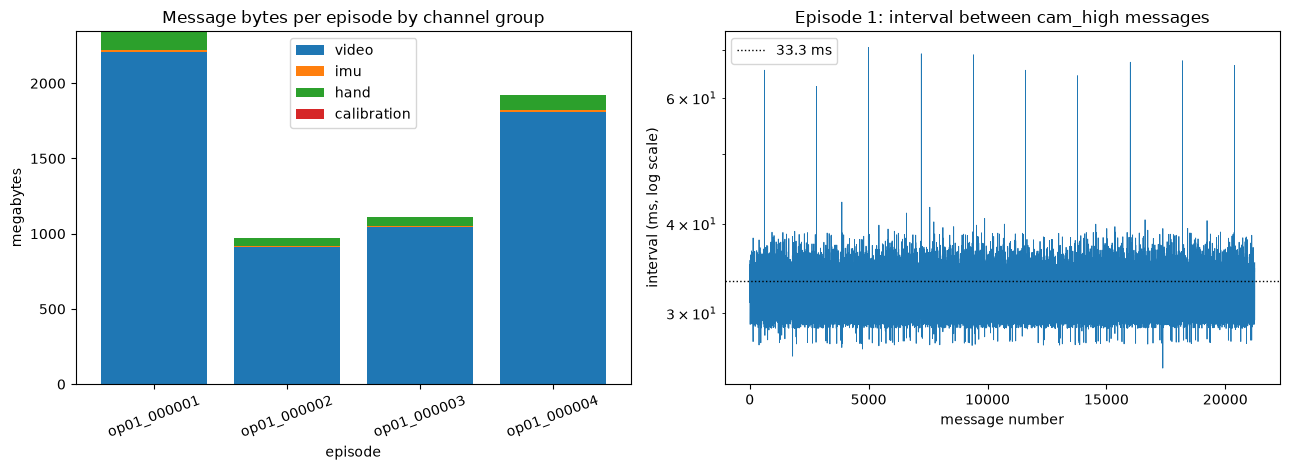

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
groups = ["video", "imu", "hand", "calibration"]
bottom = np.zeros(len(ids))
for g in groups:
    vals = np.array([EXTRA.get(e, {}).get("groups", {}).get(g, 0) / 1e6 for e in ids])
    ax[0].bar(range(len(ids)), vals, bottom=bottom, label=g)
    bottom += vals
ax[0].set_xticks(range(len(ids)))
ax[0].set_xticklabels(["_".join(str(e).split("_")[-2:]) for e in ids], rotation=20)
ax[0].set_title("Message bytes per episode by channel group")
ax[0].set_xlabel("episode")
ax[0].set_ylabel("megabytes")
ax[0].legend()
ct = EXTRA.get(ids[0], {}).get("cam_high_t")
if ct is not None and len(ct) > 1:
    dt = np.maximum(np.diff(ct) / 1e6, 1e-3)
    ax[1].plot(np.arange(1, len(ct)), dt, lw=0.6)
    ax[1].set_yscale("log")
    ax[1].axhline(33.3, color="k", ls=":", lw=1, label="33.3 ms")
    ax[1].legend()
ax[1].set_title("Episode 1: interval between cam_high messages")
ax[1].set_xlabel("message number")
ax[1].set_ylabel("interval (ms, log scale)")
plt.tight_layout()
fig.savefig(REP / "12_overview.png", dpi=150)
plt.show()

## Summary and zip
Writes the summary file and the zip of all 12_ files.

In [15]:
res_by_id = {r["id"]: r["result"] for r in hyp}
summary = {"notebook": NB_NAME, "versions": VERSIONS,
           "flags": {"FORCE": FORCE, "INCLUDE_IMU": INCLUDE_IMU, "NUDGE_DUPLICATE_TS": NUDGE_DUPLICATE_TS, "NUDGE_NS": NUDGE_NS,
                     "SOURCE_FORMAT_TAG": SOURCE_FORMAT_TAG, "ROUND_DECIMALS": ROUND_DECIMALS, "COVERAGE_FLOOR_PCT": COVERAGE_FLOOR_PCT,
                     "OUT_DIR": OUT_DIR},
           "episodes": {e: {"status": STATUS.get(e), "size_bytes": FINAL.get(e, {}).get("size"), "duration_s": FINAL.get(e, {}).get("dur"),
                            "messages": FINAL.get(e, {}).get("counts"), "sha256": FINAL.get(e, {}).get("sha"),
                            "nudged_samples": {c: len(CTX[e]["nud"][c]) for c in CAMS} if e in CTX else None} for e in ids},
           "total_nudges": len(nrows), "tests": res_by_id, "run_start_utc": run_start.isoformat(),
           "run_end_utc": datetime.now(timezone.utc).isoformat(), "run_seconds": round(time.time() - t_run, 1)}
with open(REP / "12_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, default=str)

zip_path = REP / "share_12.zip"
files = []
for p in sorted(REP.iterdir()):
    if p.name.startswith("12_"):
        files += [p] if p.is_file() else [q for q in sorted(p.rglob("*")) if q.is_file()]
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in files:
        if p.suffix in (".mcap", ".part"): continue
        z.write(p, p.relative_to(REP).as_posix())

print("episodes:")
for e in ids:
    F = FINAL.get(e)
    print(f"  {e}: {STATUS.get(e)}" + (f", {F['size'] / 1e9:.3f} GB, {sum(F['counts'].values())} messages" if F else ""))
print("tests:", ", ".join(f"{k}={v}" for k, v in res_by_id.items()))
print("nudged samples:", len(nrows))
print("zip:", zip_path)

episodes:
  vendorX_2026-10-11_op01_000001: built, 2.354 GB, 191187 messages
  vendorX_2026-10-11_op01_000002: built, 0.976 GB, 84525 messages
  vendorX_2026-10-11_op01_000003: built, 1.117 GB, 93703 messages
  vendorX_2026-10-11_op01_000004: built, 1.933 GB, 162022 messages
tests: F1=PASS, F2=PASS, F3=PASS, F4=PASS, F5=PASS, F6=PASS, F6i=INFO, F7=PASS, F8=PASS, F9=PASS, F10=PASS, F11=INFO, F12=PASS, F13=INFO, F14=INFO, B1=PASS
nudged samples: 4
zip: c:\workstation\3RD YEAR\ego_pipeline\reports\share_12.zip
